# Pre-entrega 6 — Demo del Orquestador Multi-Agente (patrón Supervisor)

Este notebook muestra el **flujo de delegación** del orquestador:

1. El **Supervisor** decide quién interviene (con rúbrica de suficiencia).
2. El **Investigador** busca en las políticas de TechCorp (RAG híbrido BM25 + Pinecone).
3. El **Validador** determinístico aprueba o rechaza cada salida (procedencia, recálculo, rangos).
4. El **Analista** calcula con una calculadora segura.
5. El Supervisor decide **FINISH** → **Síntesis**, o pide **refinar**, o **escala a un humano**.

Cada paso queda en la bitácora: *quién decidió qué y por qué*.

## 1. Instalación y API keys

En Colab, primero cloná el repo (descomentá la primera línea).

In [1]:
# !git clone https://github.com/<tu-usuario>/<tu-repo>.git && %cd <tu-repo>
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from getpass import getpass
from dotenv import load_dotenv

load_dotenv()
if not os.environ.get("GOOGLE_API_KEY"):
    os.environ["GOOGLE_API_KEY"] = getpass("🔑 GOOGLE_API_KEY: ").strip()
if not os.environ.get("PINECONE_API_KEY"):
    os.environ["PINECONE_API_KEY"] = getpass("🔑 PINECONE_API_KEY (Enter para usar solo BM25): ").strip()

## 2. El grafo

Topología jerárquica: los especialistas nunca hablan entre sí; todo pasa por el Supervisor y por la puerta de calidad del Validador.

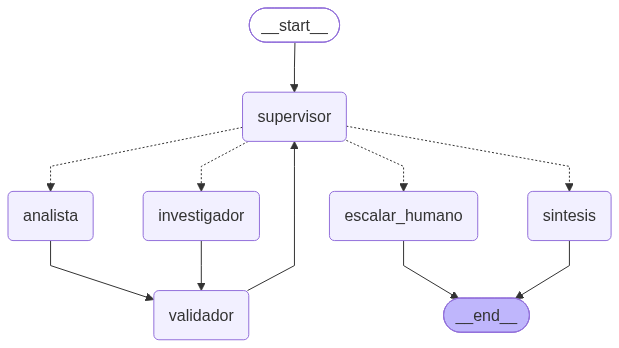

In [3]:
from IPython.display import Image, display
from main import ESCENARIOS, ejecutar
from graph import construir_grafo

marcador = object()  # el diagrama no necesita LLM
app = construir_grafo(investigador=marcador, analista=marcador, router=marcador, redactor=marcador)
display(Image(app.get_graph().draw_mermaid_png()))

## 3. Escenario 1 — Delegación completa: Investigador → Analista → FINISH

La pregunta necesita **dos dominios**: datos de la política de vacaciones (investigación) y una suma ponderada (cómputo).

In [4]:
final = await ejecutar(ESCENARIOS["vacaciones"])

Direct use of automatic function calling (AFC) in AsyncModels.generate_content is not recommended. Instead, we recommend to use AFC in AsyncChat.send_message. Similarly, direct use of AFC in AsyncModels.generate_content_stream is not recommended. Instead, we recommend to use AFC in AsyncChat.send_message_stream.


PREGUNTA: Un empleado va a cumplir 12 años en TechCorp. Tuvo los días de vacaciones que le correspondían según cada tramo de antigüedad: los primeros 5 años, los siguientes 5 y los últimos 2. ¿Cuántos días de vacaciones acumuló en total en esos 12 años?
🧭 [supervisor    ] paso 1: → investigador
                   ↳ Falla R1: No se dispone de ningún dato validado sobre la política de vacaciones de TechCorp para los diferentes tramos de antigüedad. [prompt supervisor-v1.3] | instrucción: Busca en las políticas internas de TechCorp la cantidad de días de vacaciones anuales que corresponden a los empleados según su antigüedad, detallando los tramos aplicables para los primeros 5 años, los siguientes 5 años (años


c:\Users\hecto\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1696.10it/s]


🔎 [investigador  ] intento 1: 3 hallazgo(s)
                   ↳ confianza=1.00; fuentes recuperadas=['politica_horas_extra.txt', 'politica_seguridad_informatica.txt', 'politica_teletrabajo.txt', 'politica_vacaciones.txt']
✅ [validador     ] investigador: APROBADO
🧭 [supervisor    ] paso 2: → analista
                   ↳ Se cumple R1 ya que contamos con los datos de las políticas de vacaciones por tramo de antigüedad, pero falla R2 porque aún no se ha realizado el cálculo del total de días acumulados en los 12 años. [prompt supervisor-v1.3] | instrucción: Con base en los hallazgos validados, calcula el total de días de vacaciones acumulados por el empleado en sus 12 años de servicio. El empleado tuvo: 5 años en el
🧮 [analista      ] intento 1: 5*14 + 5*21 + 2*28 = 231
                   ↳ confianza=1.00
✅ [validador     ] analista: APROBADO
🧭 [supervisor    ] paso 3: → sintesis
                   ↳ Se cumplen todas las rúbricas de suficiencia. R1 se cumple porque el investigador obtuv

### Estado compartido: quién aportó qué y qué aprobó el validador

In [6]:
print("CONTRIBUCIONES")
for c in final["contribuciones"]:
    print(f"  [{c['agente']} · intento {c['intento']}] {c['aporte'][:200]}")

print("VALIDACIONES")
for v in final["validaciones"]:
    print(f"  {v.agente:<13} {'APROBADO' if v.aprobado else 'RECHAZADO'} {v.errores}")

print("ARTEFACTO DEL INVESTIGADOR (Pydantic)")
print(final["research_output"].model_dump_json(exclude={"evidencia"}, indent=2))
print("ARTEFACTO DEL ANALISTA (Pydantic)")
print(final["analysis_output"].model_dump_json(indent=2))

CONTRIBUCIONES
  [investigador · intento 1] Se encontraron los tramos de vacaciones según la antigüedad en la política de vacaciones de TechCorp: 14 días corridos para menos de 5 años, 21 días corridos para 5 a 10 años, y 28 días corridos para 
  [analista · intento 1] 5*14 + 5*21 + 2*28 = 231. Se calcula el total de días de vacaciones acumulados multiplicando la cantidad de años en cada tramo de antigüedad por los días de vacaciones correspondientes a ese tramo. Lo
VALIDACIONES
  investigador  APROBADO []
  analista      APROBADO []
ARTEFACTO DEL INVESTIGADOR (Pydantic)
{
  "hallazgos": [
    {
      "dato": "Vacaciones para empleados con menos de 5 años de antigüedad",
      "valor": 14.0,
      "unidad": "días corridos",
      "fuente": "politica_vacaciones.txt"
    },
    {
      "dato": "Vacaciones para empleados con 5 a 10 años de antigüedad",
      "valor": 21.0,
      "unidad": "días corridos",
      "fuente": "politica_vacaciones.txt"
    },
    {
      "dato": "Vacaciones par

## 4. Escenario 2 — Porcentajes (horas extra)

Si el Analista usa un número sin procedencia (ej. `1.5` en lugar de `(1 + 50/100)`) el Validador lo rechaza y el Supervisor dispara el **bucle de reparación** con el error específico.

In [7]:
final_he = await ejecutar(ESCENARIOS["horas_extra"])

PREGUNTA: Un empleado cuya hora normal vale 12 USD hizo este mes 10 horas extra en días hábiles y 6 horas extra en un feriado. Según la política de TechCorp, ¿cuánto cobra por esas horas extra y está dentro del máximo mensual permitido?
🧭 [supervisor    ] paso 1: → investigador
                   ↳ Falla R1: No se dispone de ningún hallazgo validado sobre las políticas de TechCorp respecto al recargo de horas extra (días hábiles y feriados) ni sobre el límite máximo mensual permitido. [prompt supervisor-v1.3] | instrucción: Busca en las políticas internas de TechCorp los siguientes datos: 1) El porcentaje de recargo aplicable a las horas extra realizadas en días hábiles. 2) El porcentaje de 
🔎 [investigador  ] intento 1: FALLÓ
                   ↳ GoogleRateLimitError: Error calling model 'gemini-3.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information o

## 5. Escenario 3 — Presupuesto de capacitación

In [8]:
final_cap = await ejecutar(ESCENARIOS["capacitacion"])

PREGUNTA: Un líder de equipo de TechCorp no usó su presupuesto de capacitación el año pasado. Este año quiere hacer un curso de 2300 USD. Considerando lo máximo que puede acumular, ¿cuánto dinero le sobra o le falta?
🧭 [supervisor    ] paso 1: → investigador
                   ↳ LLM del supervisor falló (GoogleRateLimitError: Error calling model 'gemini-3.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To mon); política de respaldo. [prompt supervisor-v1.3] | 
🔎 [investigador  ] intento 1: FALLÓ
                   ↳ GoogleRateLimitError: Error calling model 'gemini-3.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head t

## 6. Camino de fallo — el Investigador se cae

Simulamos que la herramienta del Investigador no responde. El nodo captura la excepción, el Validador la rechaza, el Supervisor pide reparar hasta `MAX_REINTENTOS` y luego **escala a revisión humana** en lugar de inventar una respuesta.

In [9]:
final_fallo = await ejecutar(ESCENARIOS["vacaciones"], simular_fallo="investigador")

PREGUNTA: Un empleado va a cumplir 12 años en TechCorp. Tuvo los días de vacaciones que le correspondían según cada tramo de antigüedad: los primeros 5 años, los siguientes 5 y los últimos 2. ¿Cuántos días de vacaciones acumuló en total en esos 12 años?
🧭 [supervisor    ] paso 1: → investigador
                   ↳ LLM del supervisor falló (GoogleRateLimitError: Error calling model 'gemini-3.5-flash' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To mon); política de respaldo. [prompt supervisor-v1.3] | 
🔎 [investigador  ] intento 1: FALLÓ
                   ↳ TimeoutError: fallo simulado: la herramienta del especialista no respondió
✅ [validador     ] investigador: RECHAZADO
                   ↳ El investigador falló con una excepción: TimeoutError: fallo simulado: la herramienta 

## 7. Tests automáticos (sin API keys)

Camino feliz, reparación, números sin procedencia, alucinaciones, excepción en especialista, supervisor caído, `MAX_PASOS`, aislamiento de escritura y calculadora segura.

In [10]:
!python -m pytest -v

============================= test session starts =============================
platform win32 -- Python 3.12.10, pytest-9.1.1, pluggy-1.6.0 -- c:\Users\hecto\AppData\Local\Programs\Python\Python312\python.exe
cachedir: .pytest_cache
rootdir: c:\Curso IA Egineering\Orquestador multi-agente especializado
configfile: pytest.ini
testpaths: tests
plugins: platformdirs-4.12.2, anyio-4.14.2, langsmith-0.12.4
collecting ... collected 16 items

tests/test_orquestador.py::test_camino_feliz_investigador_analista_sintesis PASSED [  6%]
tests/test_orquestador.py::test_contexto_acotado_el_especialista_no_recibe_el_historial PASSED [ 12%]
tests/test_orquestador.py::test_analista_con_resultado_incorrecto_es_reparado_con_error_especifico PASSED [ 18%]
tests/test_orquestador.py::test_analista_que_usa_un_numero_sin_procedencia_es_rechazado PASSED [ 25%]
tests/test_orquestador.py::test_investigador_que_alucina_un_valor_es_rechazado PASSED [ 31%]
tests/test_orquestador.py::test_especialista_que_lanza_exce